# 미션 4_PyTorch 기초

텐서 조작부터 자동 미분, `nn.Module`, 학습 루프, 미니배치, 옵티마이저 비교까지 **PyTorch로 딥러닝 모델을 학습시키는 기본 흐름** 전체를 다룹니다.

| 파트 | 내용 |
| :-- | :-- |
| **1. 텐서 기초** | 생성 · 인덱싱 · 모양 변경 · 타입 변환 · 이어붙이기 · 행렬곱 · 자동 미분 · 활성화 함수 · device |
| **2. 모델 학습** | 손실 함수, 순수 autograd 선형 회귀, `nn.Module`, 2층 MLP, 학습 루프, DataLoader, 옵티마이저 · 학습률 비교 |

모든 문제는 **[확인]** `assert`로 정답을 검증하고, 학습 결과는 손실 곡선과 결정 경계로 시각화했습니다.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from matplotlib import font_manager
from matplotlib.ticker import FuncFormatter, NullFormatter
from sklearn.datasets import make_moons
from torch.utils.data import DataLoader, TensorDataset

installed = {f.name for f in font_manager.fontManager.ttflist}
for font in ["Malgun Gothic", "AppleGothic", "NanumGothic"]:
    if font in installed:
        plt.rcParams["font.family"] = font
        break
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3



def plain_log(ax):
    """로그 축 눈금을 0.01 · 0.1 · 1처럼 일반 숫자로 표시"""
    ax.set_yscale("log")
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:g}"))
    ax.yaxis.set_minor_formatter(NullFormatter())


torch.manual_seed(42)
print("PyTorch", torch.__version__, "| CUDA 사용 가능:", torch.cuda.is_available())

PyTorch 2.11.0+cu128 | CUDA 사용 가능: True


---
## Part 1. 텐서 기초

### 1-1. 텐서 생성
> 0부터 11까지의 정수를 담은 **(3, 4) 크기의 float32** 텐서

In [2]:
t1 = torch.arange(12, dtype=torch.float32).reshape(3, 4)
print(t1)

assert t1.shape == (3, 4) and t1.dtype == torch.float32 and t1[0, 0] == 0 and t1[2, 3] == 11
print("✅ 통과")

tensor([[ 0.,  1.,  2.,  3.],
        [ 4.,  5.,  6.,  7.],
        [ 8.,  9., 10., 11.]])
✅ 통과


### 1-2. 인덱싱과 슬라이싱
> 세 번째 행 · 마지막 열 · 1~2행 × 1~3열 부분 텐서

In [3]:
t2 = torch.arange(20).reshape(4, 5)

row2 = t2[2]            # 세 번째 행
col_last = t2[:, -1]    # 모든 행의 마지막 열
sub = t2[1:3, 1:4]      # 끝 인덱스는 포함하지 않는다 → (2, 3)
print(t2, row2, col_last, sub, sep="\n")

assert torch.equal(row2, torch.tensor([10, 11, 12, 13, 14]))
assert torch.equal(col_last, torch.tensor([4, 9, 14, 19]))
assert sub.shape == (2, 3) and sub[0, 0] == 6 and sub[1, 2] == 13
print("✅ 통과")

tensor([[ 0,  1,  2,  3,  4],
        [ 5,  6,  7,  8,  9],
        [10, 11, 12, 13, 14],
        [15, 16, 17, 18, 19]])
tensor([10, 11, 12, 13, 14])
tensor([ 4,  9, 14, 19])
tensor([[ 6,  7,  8],
        [11, 12, 13]])
✅ 통과


### 1-3. 모양 바꾸기: squeeze · unsqueeze · reshape
> `(3, 1, 4)` → 크기 1 차원 제거 `(3, 4)` → 맨 뒤에 차원 추가 `(3, 4, 1)` / 같은 데이터를 `(2, 6)`으로

In [4]:
t3 = torch.randn(3, 1, 4)

a = t3.squeeze(1)       # 크기가 1인 1번 차원 제거
b = a.unsqueeze(-1)     # 맨 뒤에 크기 1 차원 추가
c = t3.reshape(2, 6)    # 원소 12개를 순서 그대로 재배열
print(t3.shape, "→", a.shape, b.shape, c.shape)

assert a.shape == (3, 4) and b.shape == (3, 4, 1) and c.shape == (2, 6)
assert torch.equal(c.flatten(), t3.flatten())
print("✅ 통과")

torch.Size([3, 1, 4]) → torch.Size([3, 4]) torch.Size([3, 4, 1]) torch.Size([2, 6])
✅ 통과


### 1-4. 타입 변환
> float → long(소수점 버림) → 다시 float32

In [5]:
t4 = torch.tensor([1.7, 2.3, 3.9])

t4_long = t4.long()          # 반올림이 아니라 0 쪽으로 버림: 1.7 → 1
t4_float = t4_long.float()
print(t4_long, t4_long.dtype, "|", t4_float, t4_float.dtype)

assert t4_long.dtype == torch.int64 and torch.equal(t4_long, torch.tensor([1, 2, 3]))
assert t4_float.dtype == torch.float32
print("✅ 통과")

tensor([1, 2, 3]) torch.int64 | tensor([1., 2., 3.]) torch.float32
✅ 통과


### 1-5. 이어붙이기: cat과 stack
> `cat`은 **기존 차원**을 따라 잇고, `stack`은 **새 차원**을 만들어 쌓는다.

In [6]:
a5, b5 = torch.ones(2, 3), torch.zeros(2, 3)

cat0 = torch.cat([a5, b5], dim=0)      # (2+2, 3)
cat1 = torch.cat([a5, b5], dim=1)      # (2, 3+3)
stacked = torch.stack([a5, b5])        # 새 0번 차원 → (2, 2, 3)
print(cat0.shape, cat1.shape, stacked.shape)

assert cat0.shape == (4, 3) and cat1.shape == (2, 6) and stacked.shape == (2, 2, 3)
print("✅ 통과")

torch.Size([4, 3]) torch.Size([2, 6]) torch.Size([2, 2, 3])
✅ 통과


### 1-6. 행렬곱과 원소곱
> `@`는 행렬곱 `(2×3)·(3×4) → (2×4)`, `*`는 같은 위치끼리 곱하는 원소곱

In [7]:
m1 = torch.tensor([[1., 2., 3.], [4., 5., 6.]])
m2 = torch.ones(3, 4)
m3 = torch.full((2, 3), 2.)

mm = m1 @ m2      # 각 행의 합이 그대로 나온다: 1+2+3 = 6, 4+5+6 = 15
ew = m1 * m3
print(mm, ew, sep="\n")

assert mm.shape == (2, 4) and mm[0, 0] == 6 and mm[1, 0] == 15
assert torch.equal(ew, m1 * 2)
print("✅ 통과")

tensor([[ 6.,  6.,  6.,  6.],
        [15., 15., 15., 15.]])
tensor([[ 2.,  4.,  6.],
        [ 8., 10., 12.]])
✅ 통과


### 1-7. 자동 미분(autograd)
> $y = x^2 + 3x$의 $x = 2$에서의 기울기. 손으로 미분하면 $\frac{dy}{dx} = 2x + 3 = 7$

In [8]:
x = torch.tensor(2.0, requires_grad=True)   # 이 텐서에 대한 연산을 기록
y = x ** 2 + 3 * x
y.backward()                                # 기록된 연산을 거꾸로 따라가며 기울기 계산
grad = x.grad
print(f"autograd: {grad.item()} · 손 계산: {2 * 2 + 3}")

assert grad.item() == 7.0
print("✅ 통과")

autograd: 7.0 · 손 계산: 7
✅ 통과


### 1-8. 활성화 함수
> ReLU(음수 → 0) · Sigmoid(0~1) · Softmax(합이 1인 확률 분포)

In [9]:
z = torch.tensor([-2.0, -0.5, 0.0, 0.5, 2.0])
logits = torch.tensor([1.0, 2.0, 3.0])

relu_out = torch.relu(z)
sig_out = torch.sigmoid(z)
probs = torch.softmax(logits, dim=0)
print(relu_out, sig_out, probs, sep="\n")

assert torch.equal(relu_out, torch.tensor([0.0, 0.0, 0.0, 0.5, 2.0]))
assert abs(sig_out[2].item() - 0.5) < 1e-6 and abs(probs.sum().item() - 1.0) < 1e-6 and probs.argmax() == 2
print("✅ 통과")

tensor([0.0000, 0.0000, 0.0000, 0.5000, 2.0000])
tensor([0.1192, 0.3775, 0.5000, 0.6225, 0.8808])
tensor([0.0900, 0.2447, 0.6652])
✅ 통과


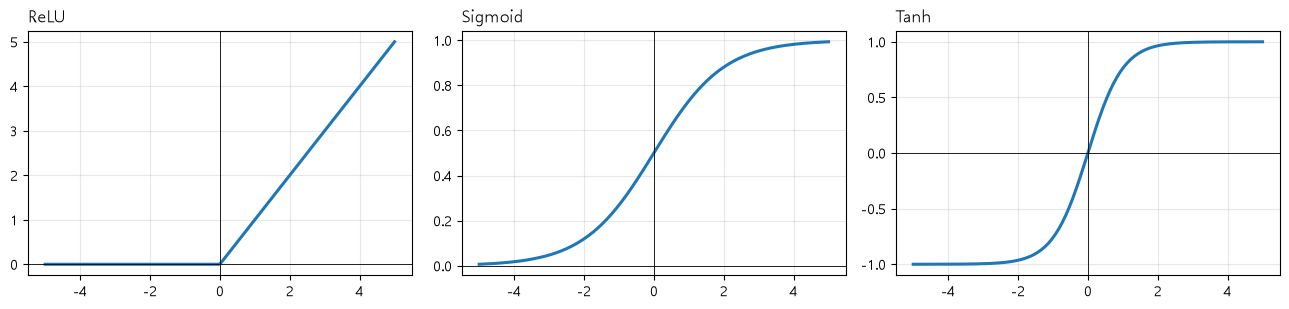

In [10]:
zz = torch.linspace(-5, 5, 200)
fig, axes = plt.subplots(1, 3, figsize=(13, 3.2))
for ax, (name, out) in zip(axes, {"ReLU": torch.relu(zz), "Sigmoid": torch.sigmoid(zz), "Tanh": torch.tanh(zz)}.items()):
    ax.plot(zz, out, linewidth=2.2)
    ax.axhline(0, color="black", linewidth=0.6)
    ax.axvline(0, color="black", linewidth=0.6)
    ax.set_title(name, loc="left")
plt.tight_layout()
plt.show()

### 1-9. device 설정
> GPU가 있으면 `cuda`, 없으면 `cpu`. 같은 코드가 어디서나 동작하게 만든다.

In [11]:
t9 = torch.randn(2, 2)

device = "cuda" if torch.cuda.is_available() else "cpu"
t9_dev = t9.to(device)
print("사용 중인 device:", device, "|", torch.cuda.get_device_name(0) if device == "cuda" else "CPU")

assert device == ("cuda" if torch.cuda.is_available() else "cpu") and t9_dev.device.type == device
print("✅ 통과")

사용 중인 device: cuda | NVIDIA GeForce RTX 3060
✅ 통과


---
## Part 2. 모델 학습

### 2-1. 손실 함수: 직접 계산 vs 내장 함수
> MSE = 오차 제곱의 평균. `CrossEntropyLoss`에는 **softmax 이전의 logits**와 **정수 라벨**을 넣는다.

In [12]:
pred, target = torch.tensor([2.5, 0.0, 2.0]), torch.tensor([3.0, -0.5, 2.0])
logits2, labels = torch.tensor([[2.0, 0.5, 0.3], [0.2, 2.5, 0.1]]), torch.tensor([0, 1])

mse_manual = ((pred - target) ** 2).mean()           # (0.25 + 0.25 + 0) / 3 = 1/6
mse_builtin = nn.MSELoss()(pred, target)
ce = nn.CrossEntropyLoss()(logits2, labels)

# CrossEntropy = 정답 클래스의 -log(softmax 확률) 평균 → 직접 계산과 비교
ce_manual = -torch.log_softmax(logits2, dim=1)[torch.arange(2), labels].mean()
print(f"MSE 직접 {mse_manual:.4f} · 내장 {mse_builtin:.4f} | CE 내장 {ce:.4f} · 직접 {ce_manual:.4f}")

assert torch.allclose(mse_manual, mse_builtin) and abs(mse_manual.item() - 1 / 6) < 1e-6
assert torch.allclose(ce, ce_manual) and ce.item() > 0
print("✅ 통과")

MSE 직접 0.1667 · 내장 0.1667 | CE 내장 0.2577 · 직접 0.2577
✅ 통과


### 2-2. 순수 autograd로 선형 회귀
> `nn.Module` 없이 $y = 2x + 1$을 학습한다. 파라미터 갱신은 그래프에 기록되지 않도록 `torch.no_grad()` 안에서, 기울기는 매 단계 0으로 초기화한다.

In [13]:
torch.manual_seed(42)
x2 = torch.linspace(0, 1, 100).unsqueeze(1)
y2 = 2 * x2 + 1 + 0.05 * torch.randn(100, 1)

lr = 0.3
w = torch.randn(1, requires_grad=True)
b = torch.zeros(1, requires_grad=True)
losses2 = []
for step in range(500):
    y_hat = x2 * w + b                      # 1) 순전파
    loss = ((y_hat - y2) ** 2).mean()
    losses2.append(loss.item())
    loss.backward()                         # 2) 역전파
    with torch.no_grad():                   # 3) 경사 하강법 (기록하지 않음)
        w -= lr * w.grad
        b -= lr * b.grad
    w.grad.zero_()                          # 4) 기울기 누적 방지
    b.grad.zero_()

print(f"학습된 w = {w.item():.3f} (정답 2) · b = {b.item():.3f} (정답 1) · 최종 손실 {losses2[-1]:.5f}")
assert abs(w.item() - 2) < 0.2 and abs(b.item() - 1) < 0.2 and losses2[-1] < 0.02
print("✅ 통과")

학습된 w = 1.997 (정답 2) · b = 1.004 (정답 1) · 최종 손실 0.00241
✅ 통과


### 2-3. `nn.Module`로 선형 회귀
> 같은 문제를 PyTorch 표준 방식(`nn.Linear` + 옵티마이저)으로. 파라미터 등록과 갱신을 PyTorch가 대신한다.

In [14]:
class LinearRegression(nn.Module):
    def __init__(self):
        super().__init__()
        self.linear = nn.Linear(1, 1)     # 가중치·편향이 자동으로 파라미터로 등록됨

    def forward(self, x):
        return self.linear(x)


torch.manual_seed(42)
model3 = LinearRegression()
criterion = nn.MSELoss()
optimizer = torch.optim.SGD(model3.parameters(), lr=0.3)
for epoch in range(500):
    optimizer.zero_grad()
    loss = criterion(model3(x2), y2)
    loss.backward()
    optimizer.step()

print(f"학습된 weight = {model3.linear.weight.item():.3f} · bias = {model3.linear.bias.item():.3f}")
for name, p in model3.named_parameters():
    print(f"  {name:<14} {tuple(p.shape)}  {type(p).__name__}")

assert isinstance(model3.linear, nn.Linear)
assert abs(model3.linear.weight.item() - 2) < 0.2 and abs(model3.linear.bias.item() - 1) < 0.2
print("✅ 통과")

학습된 weight = 1.997 · bias = 1.004
  linear.weight  (1, 1)  Parameter
  linear.bias    (1,)  Parameter
✅ 통과


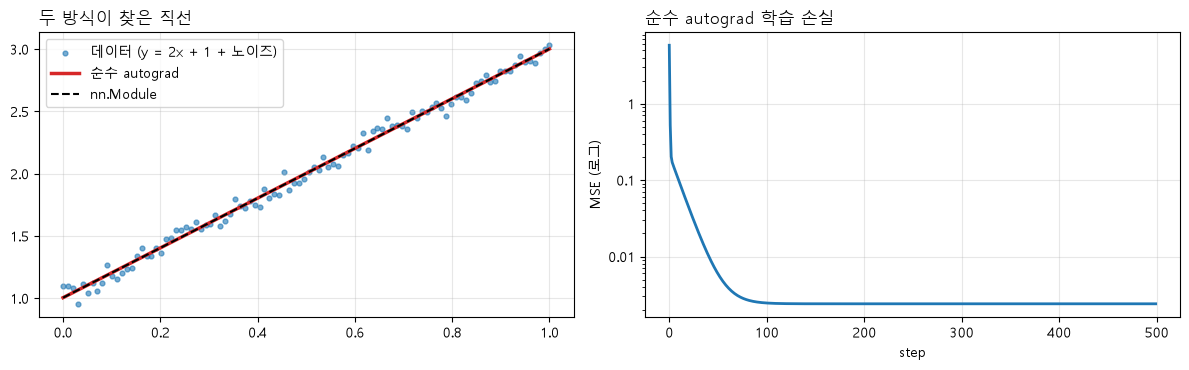

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].scatter(x2, y2, s=12, alpha=0.6, label="데이터 (y = 2x + 1 + 노이즈)")
with torch.no_grad():
    axes[0].plot(x2, x2 * w + b, color="tab:red", linewidth=2.5, label="순수 autograd")
    axes[0].plot(x2, model3(x2), color="black", linestyle="--", linewidth=1.5, label="nn.Module")
axes[0].legend()
axes[0].set_title("두 방식이 찾은 직선", loc="left")
axes[1].plot(losses2, linewidth=2)
plain_log(axes[1])
axes[1].set_xlabel("step")
axes[1].set_ylabel("MSE (로그)")
axes[1].set_title("순수 autograd 학습 손실", loc="left")
plt.tight_layout()
plt.show()

두 방식은 같은 시드와 같은 학습률에서 **같은 직선**을 찾습니다. `nn.Module`과 옵티마이저는 2-2에서 직접 작성한 순전파 · 갱신 · 기울기 초기화를 **표준화해 감싼 것**입니다.

### 2-4. 2층 MLP 분류 모델
> 초승달 데이터(`make_moons`)를 분류하는 `2 → 16 → ReLU → 2` 구조. 출력에 softmax를 붙이지 않는다(손실 함수가 처리).

In [16]:
X_np, y_np = make_moons(n_samples=500, noise=0.2, random_state=42)
X = torch.tensor(X_np, dtype=torch.float32)
y = torch.tensor(y_np, dtype=torch.long)


class MLP(nn.Module):
    def __init__(self, hidden=16):
        super().__init__()
        self.fc1 = nn.Linear(2, hidden)
        self.fc2 = nn.Linear(hidden, 2)

    def forward(self, x):
        return self.fc2(F.relu(self.fc1(x)))


model4 = MLP()
n_params = sum(p.numel() for p in model4.parameters())
print(model4)
print(f"파라미터 수: (2×16 + 16) + (16×2 + 2) = {n_params}")

assert model4(X[:5]).shape == (5, 2) and n_params == 82
print("✅ 통과")

MLP(
  (fc1): Linear(in_features=2, out_features=16, bias=True)
  (fc2): Linear(in_features=16, out_features=2, bias=True)
)
파라미터 수: (2×16 + 16) + (16×2 + 2) = 82
✅ 통과


### 2-5. 학습 루프
> 기울기 초기화 → 순전파 → 손실 → 역전파 → 갱신. 이 다섯 단계가 모든 PyTorch 학습의 뼈대다.

In [17]:
torch.manual_seed(42)
model5 = MLP()
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model5.parameters(), lr=0.01)

losses5 = []
for epoch in range(300):
    optimizer.zero_grad()              # 1) 기울기 초기화
    logits = model5(X)                 # 2) 순전파
    loss = criterion(logits, y)        # 3) 손실
    loss.backward()                    # 4) 역전파
    optimizer.step()                   # 5) 갱신
    losses5.append(loss.item())

with torch.no_grad():
    acc = (model5(X).argmax(dim=1) == y).float().mean().item()
print(f"최종 손실 {losses5[-1]:.4f} · 학습 정확도 {acc:.3f}")
assert acc > 0.85
print("✅ 통과")

최종 손실 0.0670 · 학습 정확도 0.980
✅ 통과


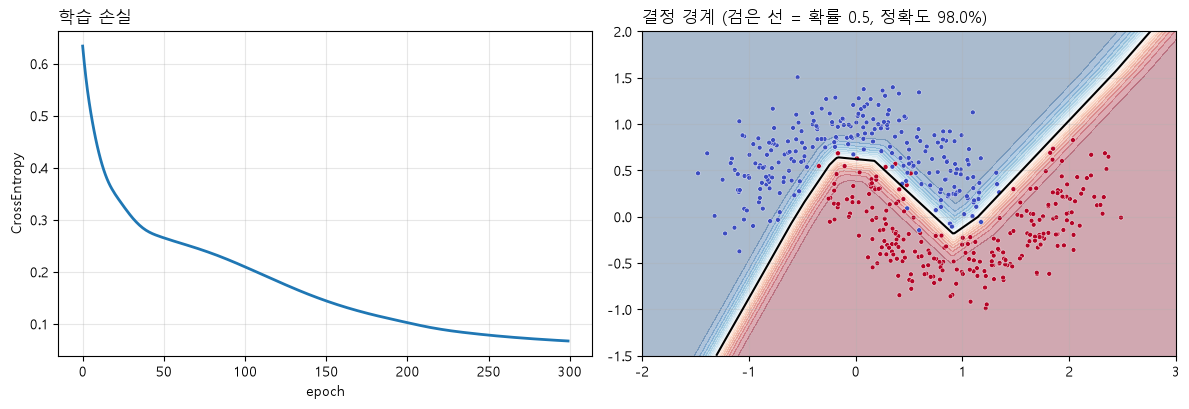

In [18]:
def plot_boundary(model, ax, title):
    """2차원 평면 전체에 대한 예측을 칠해 결정 경계를 그린다."""
    xx, yy = np.meshgrid(np.linspace(-2, 3, 300), np.linspace(-1.5, 2, 300))
    grid = torch.tensor(np.c_[xx.ravel(), yy.ravel()], dtype=torch.float32)
    with torch.no_grad():
        prob = torch.softmax(model(grid), dim=1)[:, 1].reshape(xx.shape)
    ax.contourf(xx, yy, prob, levels=20, cmap="RdBu_r", alpha=0.35)
    ax.contour(xx, yy, prob, levels=[0.5], colors="black", linewidths=1.5)
    ax.scatter(X[:, 0], X[:, 1], c=y, cmap="coolwarm", s=12, edgecolor="white", linewidth=0.3)
    ax.set_title(title, loc="left")


fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
axes[0].plot(losses5, linewidth=2)
axes[0].set_xlabel("epoch")
axes[0].set_ylabel("CrossEntropy")
axes[0].set_title("학습 손실", loc="left")
plot_boundary(model5, axes[1], f"결정 경계 (검은 선 = 확률 0.5, 정확도 {acc:.1%})")
plt.tight_layout()
plt.show()

은닉층 하나와 ReLU만으로 직선이 아닌 **곡선 경계**를 학습했습니다. 은닉층 없이 선형 층 하나만 쓰면 직선 경계밖에 만들 수 없어 두 초승달을 깔끔하게 나눌 수 없습니다.

### 2-6. DataLoader로 미니배치 학습
> 500개를 한 번에 넣지 않고 64개씩 나눠 학습한다. 한 epoch에 8번 갱신된다(500 / 64 → 8개 배치).

In [19]:
dataset = TensorDataset(X, y)
loader = DataLoader(dataset, batch_size=64, shuffle=True)

torch.manual_seed(42)
model6 = MLP()
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model6.parameters(), lr=0.01)

losses6 = []
for epoch in range(100):
    epoch_loss = 0.0
    for xb, yb in loader:
        optimizer.zero_grad()
        logits = model6(xb)
        loss = criterion(logits, yb)
        loss.backward()
        optimizer.step()
        epoch_loss += loss.item() * len(xb)
    losses6.append(epoch_loss / len(dataset))

with torch.no_grad():
    acc6 = (model6(X).argmax(dim=1) == y).float().mean().item()
print(f"배치 수 {len(loader)} · 최종 손실 {losses6[-1]:.4f} · 학습 정확도 {acc6:.3f}")
assert len(dataset) == 500 and loader.batch_size == 64 and len(loader) == 8 and acc6 > 0.85
print("✅ 통과")

배치 수 8 · 최종 손실 0.0586 · 학습 정확도 0.982
✅ 통과


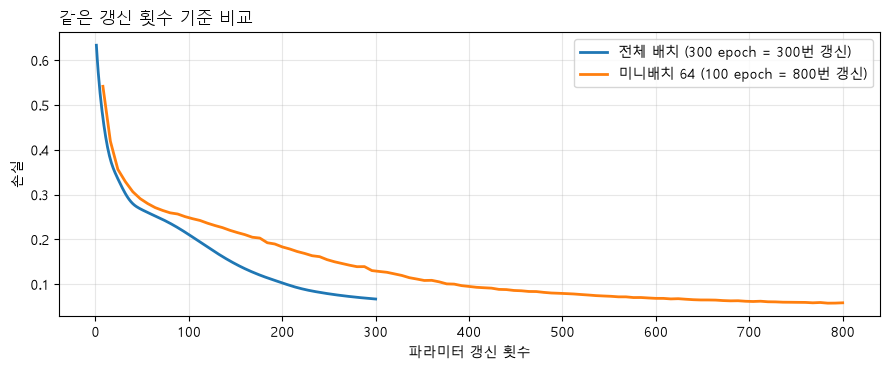

300번 갱신 시점 손실 · 전체 배치 0.0670 vs 미니배치 0.1305
계산량(샘플 처리 수) · 전체 배치 300 epoch = 150,000 → 손실 0.0670 | 미니배치 100 epoch = 50,000 → 손실 0.0586


In [20]:
fig, ax = plt.subplots(figsize=(9, 3.8))
updates5 = np.arange(1, len(losses5) + 1)              # 전체 배치: epoch당 1번 갱신
updates6 = np.arange(1, len(losses6) + 1) * len(loader)  # 미니배치: epoch당 8번 갱신
ax.plot(updates5, losses5, label="전체 배치 (300 epoch = 300번 갱신)", linewidth=2)
ax.plot(updates6, losses6, label="미니배치 64 (100 epoch = 800번 갱신)", linewidth=2)
ax.set_xlabel("파라미터 갱신 횟수")
ax.set_ylabel("손실")
ax.set_title("같은 갱신 횟수 기준 비교", loc="left")
ax.legend()
plt.tight_layout()
plt.show()
print(f"300번 갱신 시점 손실 · 전체 배치 {losses5[299]:.4f} vs 미니배치 {losses6[300 // len(loader) - 1]:.4f}")
print(f"계산량(샘플 처리 수) · 전체 배치 300 epoch = {300 * 500:,} → 손실 {losses5[-1]:.4f} | 미니배치 100 epoch = {100 * 500:,} → 손실 {losses6[-1]:.4f}")

- **같은 갱신 횟수**로 비교하면 전체 배치가 더 낮습니다. 미니배치의 기울기는 64개로 추정한 값이라 잡음이 있기 때문입니다.
- **같은 계산량**으로 보면 이야기가 달라집니다. 미니배치는 데이터를 1/3만 처리하고도(100 epoch) 전체 배치 300 epoch보다 손실이 낮습니다. 갱신 한 번이 싸서 같은 계산으로 더 자주 갱신할 수 있기 때문이며, 데이터가 커질수록 이 차이는 결정적입니다.

### 2-7. 옵티마이저와 학습률 비교
> 같은 모델 · 같은 초기값에서 `SGD 0.01` · `SGD 0.5` · `SGD 10.0` · `Adam 0.01`로 200 epoch 학습

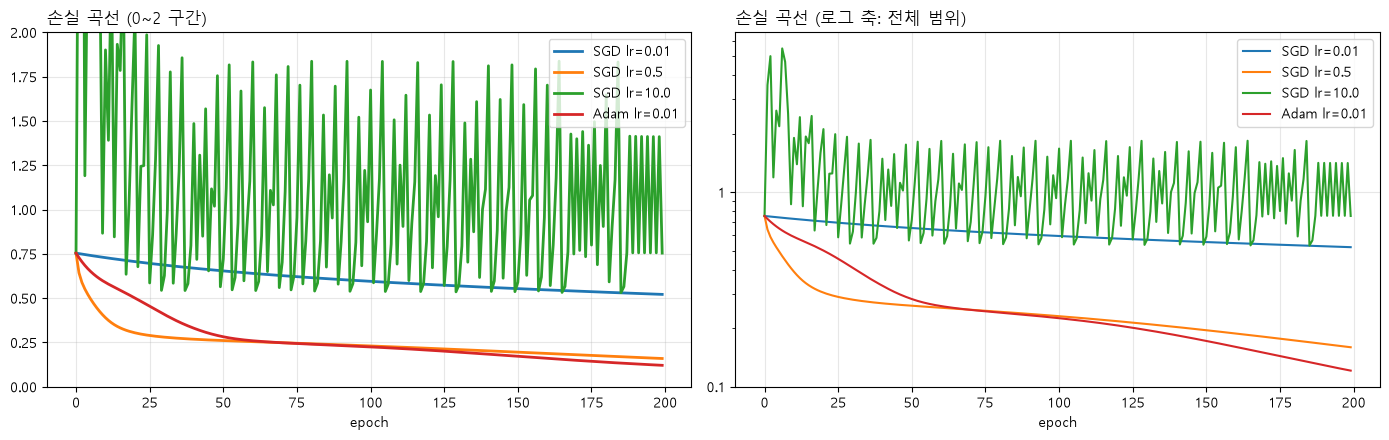

In [21]:
def train_with(optimizer_fn, epochs=200):
    """같은 초기값(seed 0)의 MLP를 주어진 옵티마이저로 학습하고 손실 기록을 반환한다."""
    torch.manual_seed(0)
    model = MLP()
    criterion = nn.CrossEntropyLoss()
    optimizer = optimizer_fn(model.parameters())
    losses = []
    for _ in range(epochs):
        optimizer.zero_grad()
        loss = criterion(model(X), y)
        loss.backward()
        optimizer.step()
        losses.append(loss.item())
    with torch.no_grad():
        accuracy = (model(X).argmax(1) == y).float().mean().item()
    trained[repr(optimizer_fn)] = model
    return losses, accuracy


settings = {
    "SGD lr=0.01": lambda p: torch.optim.SGD(p, lr=0.01),
    "SGD lr=0.5": lambda p: torch.optim.SGD(p, lr=0.5),
    "SGD lr=10.0": lambda p: torch.optim.SGD(p, lr=10.0),
    "Adam lr=0.01": lambda p: torch.optim.Adam(p, lr=0.01),
}
results, accuracies, models, trained = {}, {}, {}, {}
for name, fn in settings.items():
    results[name], accuracies[name] = train_with(fn)
    models[name] = trained[repr(fn)]
assert all(len(v) == 200 for v in results.values())

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for name, losses in results.items():
    axes[0].plot(losses, label=name, linewidth=2)
    axes[1].plot(losses, label=name, linewidth=1.5)
axes[0].set_ylim(0, 2)
axes[0].set_title("손실 곡선 (0~2 구간)", loc="left")
plain_log(axes[1])
axes[1].set_title("손실 곡선 (로그 축: 전체 범위)", loc="left")
for ax in axes:
    ax.set_xlabel("epoch")
    ax.legend()
plt.tight_layout()
plt.show()

In [22]:
import pandas as pd

rows = []
for name, losses in results.items():
    arr = np.array(losses)
    reach = np.where(arr < 0.3)[0]
    rows.append({"설정": name, "최종 손실": arr[-1], "최소 손실": arr.min(), "최대 손실": arr.max(),
                 "손실 0.3 도달 epoch": int(reach[0]) + 1 if len(reach) else "도달 못함",
                 "마지막 50 epoch 손실 표준편차": arr[-50:].std(), "최종 정확도": accuracies[name]})
summary = pd.DataFrame(rows).set_index("설정")
summary.style.format({"최종 손실": "{:.4f}", "최소 손실": "{:.4f}", "최대 손실": "{:.3g}",
                      "마지막 50 epoch 손실 표준편차": "{:.4f}", "최종 정확도": "{:.1%}"})

,최종 손실,최소 손실,최대 손실,손실 0.3 도달 epoch,마지막 50 epoch 손실 표준편차,최종 정확도
설정,,,,,,
SGD lr=0.01,0.5211,0.5211,0.754,도달 못함,0.0095,83.4%
SGD lr=0.5,0.1593,0.1593,0.754,23,0.0105,93.6%
SGD lr=10.0,0.7541,0.5312,5.48,도달 못함,0.4001,70.4%
Adam lr=0.01,0.1208,0.1208,0.754,47,0.0151,96.0%


In [23]:
# lr=10에서 무슨 일이 일어났는가: 은닉 뉴런 16개 중 모든 입력에서 출력이 0인(죽은) ReLU 개수
dead = {}
with torch.no_grad():
    for name, model in models.items():
        hidden = F.relu(model.fc1(X))
        dead[name] = int((hidden.max(dim=0).values == 0).sum())
arr10 = np.array(results["SGD lr=10.0"])
print("죽은 ReLU 뉴런 수 (16개 중):", dead)
print("SGD lr=10.0 처음 10 epoch 손실:", np.round(arr10[:10], 3).tolist())

죽은 ReLU 뉴런 수 (16개 중): {'SGD lr=0.01': 2, 'SGD lr=0.5': 2, 'SGD lr=10.0': 9, 'Adam lr=0.01': 5}
SGD lr=10.0 처음 10 epoch 손실: [0.754, 3.554, 5.003, 1.191, 2.624, 2.181, 5.481, 4.677, 2.527, 0.866]


### 2-7 서술: 측정값으로 답하기

**1. 가장 빠르고 안정적으로 수렴한 설정은?**
- **200 epoch 결과 기준으로는 `Adam lr=0.01`입니다.**
  - 최종 손실이 0.121로 가장 낮고, 정확도도 96.0%로 가장 높습니다.
  - 마지막 50 epoch 손실의 표준편차가 0.015로 안정적입니다.
- **초반 속도만 보면 `SGD lr=0.5`가 더 빠릅니다.** 손실 0.3에 23 epoch 만에 도달했고, Adam은 47 epoch이 걸렸습니다.
  - 학습률이 잘 맞으면 SGD도 빠르지만, 끝까지 가면 Adam이 더 낮은 손실에 도달합니다.
- `SGD lr=0.01`은 보폭이 너무 작아 200 epoch 동안 손실이 0.52에 머물렀습니다.

**2. `SGD lr=10.0`에서는 무슨 일이 일어났나?**
- **진동하며 수렴하지 못했습니다.**
  - 첫 갱신에서 손실이 0.754 → 3.55로 오히려 커졌습니다.
  - 이후 0.5~5.5 사이를 오갔고, 마지막 50 epoch 표준편차는 0.40으로, 다른 설정(0.010~0.015)보다 25배 이상 큽니다.
  - 최종 정확도는 70.4%에 그쳤습니다.
- **이유는 overshooting입니다.** 갱신량은 `학습률 × 기울기`입니다. 학습률이 너무 크면 손실이 줄어드는 방향으로 가더라도 최솟값을 **훌쩍 건너뛰어** 반대편의 더 높은 지점에 떨어지고, 이것이 반복됩니다.
- **부작용도 생겼습니다.** 큰 갱신이 은닉층 가중치를 크게 흔들어, 16개 뉴런 중 9개가 모든 입력에 0만 출력하는 **죽은 ReLU**가 되었습니다(SGD 0.5는 2개). 죽은 뉴런은 기울기가 0이라 다시 살아나지 못하므로 모델의 표현력이 줄어듭니다.

**3. Adam은 SGD와 무엇이 다른가?**

| | SGD | Adam |
| :-- | :-- | :-- |
| 이동 방향 | 현재 기울기만 사용 | **모멘텀**: 기울기의 지수이동평균(1차 모멘트). 일관된 방향은 가속하고, 지그재그 진동은 상쇄 |
| 보폭 | 모든 파라미터에 같은 고정 학습률 | **RMSProp**: **기울기 제곱**의 지수이동평균(2차 모멘트)으로 나눠 파라미터마다 보폭을 자동 조절. 기울기가 큰 파라미터는 작게, 작은 파라미터는 크게 이동 |
| 초기 보정 | 없음 | 두 평균이 0에서 시작하는 편향을 보정 |

그래서 **같은 학습률 0.01**에서도 SGD는 손실 0.52, Adam은 0.12까지 내려갔습니다. Adam은 학습률 선택에 덜 민감하다는 장점이 있습니다. 다만 위 결과처럼 학습률이 잘 맞는 SGD가 초반에 더 빠를 수 있어, 둘 중 어느 쪽이 항상 낫다고 할 수는 없습니다.